# Практический проект: Автоэнкодер (AE) для анализа снимков сетчатки (OCTMNIST)

**Тема работы:** Построение полносвязного автоэнкодера (AE) для сжатия, реконструкции и анализа скрытых признаков медицинских изображений оптической когерентной томографии (ОКТ).

**Обоснование выбора архитектуры и данных:**
- Датасет **OCTMNIST** содержит реальные медицинские снимки сетчатки глаза (4 клинических класса: `CNV`, `DME`, `DRUSEN`, `NORMAL`), приведённые к размеру **64×64** пикселей.
- Полносвязный автоэнкодер быстро обучается и позволяет наглядно оценить как качество восстановления анатомических слоёв сетчатки, так и структуру латентного пространства.
- Проект охватывает полный цикл разработки ML-решения: от формулирования устава и планирования задач до проведения серии экспериментов, анализа метрик и ретроспективы.

In [ ]:
#Импорт библиотек и настройка окружения
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cuda | Torch: 2.14.1+cu130


## 1. Project Charter (устав проекта)

Краткое резюме работы: какую задачу решаем, какой результат планируем получить и какие есть ограничения.

| Раздел | Описание |
| :--- | :--- |
| **Название проекта** | AE для сжатия снимков сетчатки глаза |
| **Инициатор / заказчик** | Индивидуальная практическая работа в рамках курса по Нейронным сетям |
| **Постановка проблемы** | Необходимо переводить ОКТ-изображения сетчатки (64×64 пикселей, 4096 признаков) в компактный векторный формат для группировки и визуального анализа патологий |
| **Цель (SMART)** | Обучить модель AE с ошибкой реконструкции MSE < 0.02 на тестовой выборке OCTMNIST и сжать признаки до размерностей `2`, `8` и `32` для оценки качества восстановления и построения карты классов |
| **Входит в scope** | Загрузка данных из Hugging Face (`OctoMed/OCTMNIST`), сборка базового автоэнкодера (Vanilla AE), сравнение `latent_dim ∈ {2, 8, 32}`, визуализация реконструкций, PCA и t-SNE |
| **Не входит в scope** | Генеративные и условные модификации (VAE, CVAE), проверка на других медицинских наборах (PathMNIST) и развёртывание модели как отдельного сервиса |
| **Участники проекта** | Автор работы (студенты: Бабаев Ф.А., Нарнова М.А.),преподаватель и условный специалист по анализу медицинских изображений |
| **Критерии результата** | Ошибка MSE < 0.02 на тесте; восстановленные снимки сохраняют контуры слоёв сетчатки, а в латентном пространстве прослеживается разделение классов |
| **Технические рамки** | Обучение на ресурсах Google Colab (CPU / GPU) за 5 эпох, минимальный стек библиотек (`torch`, `torchvision`, `datasets`, `scikit-learn`) |

## 2. WBS (Work Breakdown Structure) и Roadmap

**WBS** — декомпозиция проекта на конкретные этапы и задачи для контроля прогресса.

```
1. Инициализация
   1.1. Определение целей, границ и ограничений проекта (Charter)
   1.2. Выбор метрики качества (MSE) и целевых порогов
2. Работа с данными
   2.1. Загрузка датасета OctoMed/OCTMNIST через библиотеку datasets
   2.2. Разведочный анализ (EDA): просмотр примеров по всем 4 классам (CNV, DME, DRUSEN, NORMAL)
   2.3. Написание кастомного PyTorch Dataset: перевод в оттенки серого (1 канал) и ресайз до 64×64
3. Разработка модели
   3.1. Проектирование симметричной полносвязной архитектуры (4096 → 256 → 64 → latent_dim → 64 → 256 → 4096)
   3.2. Реализация цикла обучения и функции валидации на тестовой выборке (1000 снимков)
4. Серия экспериментов
   4.1. Обучение моделей с размером скрытого слоя latent_dim ∈ {2, 8, 32} в течение 5 эпох
   4.2. Логирование метрик (train/val MSE), числа параметров и времени в pandas.DataFrame
   4.3. Визуализация кривых обучения, сравнение реконструкций и проекций (2D, PCA, t-SNE)
5. Подведение итогов
   5.1. Сравнение полученных метрик с целевым показателем (MSE < 0.02)
   5.2. Формулирование выводов и идей по улучшению архитектуры (Backlog)
```

**Roadmap (план-график выполнения):**

| Этап | Задачи | Исполнитель | Статус |
| :--- | :--- | :--- | :---: |
| День 1 | Формирование устава (Charter) и структуры задач (WBS) | Авторы проекта | ✅ |
| День 1 | Подключение `OctoMed/OCTMNIST`, создание `OCTMNISTDataset` и `DataLoader` | Авторы проекта | ✅ |
| День 2 | Написание класса `AE` на PyTorch и отладка цикла обучения | Авторы проекта | ✅ |
| День 2 | Проведение серии запусков для `latent_dim` = 2, 8 и 32 (5 эпох) | Авторы проекта | ✅ |
| День 3 | Визуализация реконструкций (64×64), построение графиков PCA и t-SNE | Авторы проекта | ✅ |
| День 3 | Оформление итоговых выводов и ретроспективы | Авторы проекта | ✅ |

## 3. Kanban board и Risk register

**Kanban-доска** отражает распределение и статус задач в ходе работы над проектом.

### Backlog (на перспективу)
- [ ] Заменить полносвязные слои на свёрточные (ConvAE) для более чёткой передачи мелких патологий сетчатки
- [ ] Реализовать вариационный автоэнкодер (VAE) для генерации синтетических ОКТ-снимков
- [ ] Сравнить качество сжатия автоэнкодера с классическим методом главных компонент (PCA)

### In Progress (в работе)
- [x] Сравнительные запуски с разным размером скрытого слоя (`latent_dim ∈ {2, 8, 32}`)
- [x] Построение 2D-проекций латентного пространства с помощью PCA и t-SNE

### Done (выполнено)
- [x] Оформлен устав проекта (Project Charter) и план работ (WBS)
- [x] Реализован пайплайн загрузки и предобработки 108 309 обучающих и 1 000 тестовых снимков
- [x] Проведён первичный осмотр (EDA) всех 4 клинических классов
- [x] Обучены модели и зафиксированы итоговые метрики

**Реестр рисков (Risk register):**

| Возможный риск | Вероятность | Критичность | Способ снижения риска |
| :--- | :---: | :---: | :--- |
| Высокая вычислительная нагрузка из-за размера 64×64 (4096 входов) | Высокая | Средняя | Ограничить обучение 5 эпохами и использовать батч размера 128 |
| Размытие мелких структур сетчатки при экстремальном сжатии (`dim=2`) | Высокая | Средняя | Провести параллельные тесты с размерностями `dim=8` и `dim=32` |
| Переобучение на большом обучающем наборе (108 тыс. снимков) | Низкая | Высокая | Отслеживать ошибку на независимой тестовой выборке после каждой эпохи |
| Сильное перемешивание классов в 2D-пространстве при обучении без учителя | Средняя | Средняя | Дополнительно проверить разделение классов на 32-мерных эмбеддингах через t-SNE |

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms
from datasets import load_dataset

hf_dataset = load_dataset("OctoMed/OCTMNIST")

ANSWER_TO_LABEL = {
    "A: Choroidal neovascularization": 0,
    "B: Diabetic macular edema": 1,
    "C: Drusen": 2,
    "D: Normal": 3,
}

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

def build_tensor_dataset(split):
    imgs, labels = [], []
    for item in hf_dataset[split]:
        img = transform(item['image'])
        if img.shape[0] == 3:
            img = transforms.functional.rgb_to_grayscale(img)
        raw_answer = item.get('answer', None)
        label = ANSWER_TO_LABEL.get(str(raw_answer).strip(), 0) if raw_answer else 0
        imgs.append(img)
        labels.append(label)
    return TensorDataset(torch.stack(imgs), torch.tensor(labels, dtype=torch.long))


train_ds = build_tensor_dataset('train')
test_ds = build_tensor_dataset('test')

IMG_CHANNELS, IMG_SIZE = 1, 64
BATCH_SIZE = 256

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, pin_memory=True)

class_names = ['CNV', 'DME', 'DRUSEN', 'NORMAL']
print("Готово! Train:", len(train_ds), "Test:", len(test_ds))


Готово! Train: 108309 Test: 1000


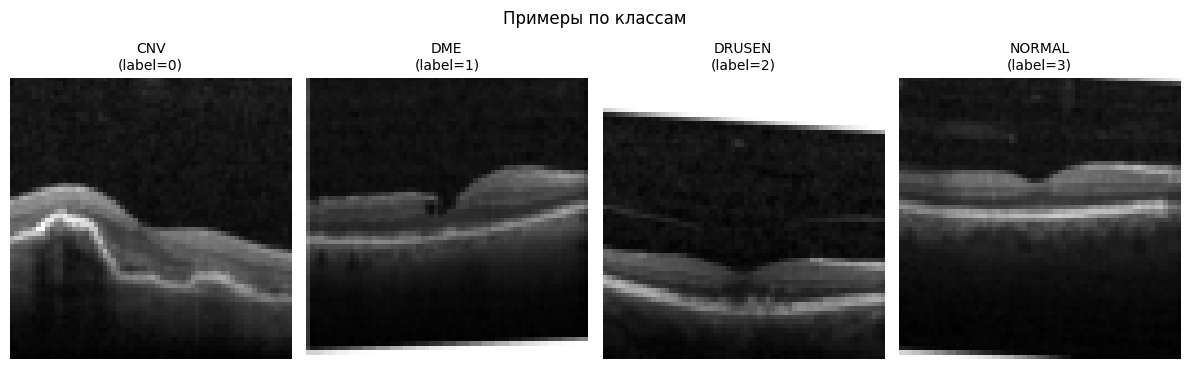

In [ ]:
#EDA (примеры по классам)
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

labels_tensor = train_ds.tensors[1]

for cls_idx, ax in enumerate(axes.ravel()):
    matches = (labels_tensor == cls_idx).nonzero(as_tuple=True)[0]
    if len(matches) > 0:
        found_idx = matches[0].item()
        img, label = train_ds[found_idx]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(f"{class_names[cls_idx]}\n(label={label.item()})", fontsize=10)
    else:
        ax.text(0.5, 0.5, f'Class "{class_names[cls_idx]}"\nnot found',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title(class_names[cls_idx], fontsize=10)
    ax.axis("off")

plt.suptitle("Примеры по классам")
plt.tight_layout()
plt.show()


In [ ]:
#Определение модели Autoencoder
class AE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        input_dim = IMG_CHANNELS * IMG_SIZE * IMG_SIZE
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 256), nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, input_dim), nn.Sigmoid(),
            nn.Unflatten(1, (IMG_CHANNELS, IMG_SIZE, IMG_SIZE)),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

_m = AE(latent_dim=32).to(device)
with torch.no_grad():
    x_hat, z = _m(torch.randn(4, IMG_CHANNELS, IMG_SIZE, IMG_SIZE).to(device))
print("x_hat:", x_hat.shape, "| z:", z.shape)
print("Параметров:", sum(p.numel() for p in _m.parameters()))

x_hat: torch.Size([4, 1, 64, 64]) | z: torch.Size([4, 32])
Параметров: 2138784


In [ ]:
#Функции обучения и оценки
@torch.no_grad()
def eval_loss(model, loader, criterion):
    model.eval()
    total = 0.0
    for xb, _ in loader:
        xb = xb.to(device)
        x_hat, _ = model(xb)
        total += criterion(x_hat, xb).item() * xb.size(0)
    return total / len(loader.dataset)

def train_ae(latent_dim=32, epochs=10, lr=1e-3, verbose=True):
    model = AE(latent_dim=latent_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    history = {"epoch": [], "train_loss": [], "val_loss": [], "time": []}
    run_id = f"ld{latent_dim}_lr{lr}_ep{epochs}"

    for ep in range(epochs):
        t0 = time.time()
        model.train()
        running = 0.0
        for xb, _ in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            x_hat, _ = model(xb)
            loss = criterion(x_hat, xb)
            loss.backward()
            optimizer.step()
            running += loss.item() * xb.size(0)

        tr = running / len(train_loader.dataset)
        va = eval_loss(model, test_loader, criterion)
        dt = time.time() - t0

        history["epoch"].append(ep + 1)
        history["train_loss"].append(tr)
        history["val_loss"].append(va)
        history["time"].append(dt)

        if verbose and ((ep + 1) % 2 == 0 or ep == 0):
            print(f"[{run_id}] epoch {ep+1:02d}/{epochs} | train {tr:.4f} | val {va:.4f} | {dt:.1f}s")

    return model, history, run_id

## 4. Experiment log и Definition of Done

**Журнал экспериментов (Experiment log)** — сводная таблица для систематизации параметров и результатов всех запусков. В данном ноутбуке метрики собираются автоматически в `results_df` (`pandas.DataFrame`).

Фиксируемые параметры:
- `run_id` — идентификатор запуска (`ld2_lr0.001_ep5`, `ld8_lr0.001_ep5`, `ld32_lr0.001_ep5`)
- `latent_dim` — размерность латентного пространства (`2`, `8` или `32`)
- `epochs` — количество эпох обучения (`5`)
- `final_train_loss` / `final_val_loss` — итоговая ошибка реконструкции MSE на обучении и тесте
- `total_time_s` / `params` — суммарное время обучения в секундах и общее число параметров (~2.13 млн)

**Критерии готовности проекта (Definition of Done):**

- Код всех ячеек выполняется последовательно без ошибок, функция потерь стабильно снижается.
- Целевой порог `MSE < 0.02` достигнут во всех трёх конфигурациях (`0.00985` для `dim=2`, `0.00522` для `dim=8` и `0.00461` для `dim=32`).
- Построены графики кривых обучения и времени на эпоху.
- Визуализированы пары «оригинал — реконструкция» (размер 64×64) для модели с `latent_dim=32`.
- Построены карты латентного пространства (прямой график для `dim=2` и проекции PCA/t-SNE для `dim=32`).
- Сформулированы выводы по итогам работы.

In [ ]:
#Эксперименты с разными размерностями латентного пространства
results = []
models = {}
histories = {}

EPOCHS = 5
LATENT_DIMS = [2, 8, 32]

for ld in LATENT_DIMS:
    print(f"\nlatent_dim = {ld}")
    model, hist, run_id = train_ae(latent_dim=ld, epochs=EPOCHS, lr=1e-3)
    models[ld] = model
    histories[ld] = hist
    results.append({
        "run_id": run_id,
        "latent_dim": ld,
        "epochs": len(hist["epoch"]),
        "final_train_loss": round(hist["train_loss"][-1], 5),
        "final_val_loss": round(hist["val_loss"][-1], 5),
        "total_time_s": round(sum(hist["time"]), 1),
        "params": sum(p.numel() for p in model.parameters()),
    })

results_df = pd.DataFrame(results)
display(results_df)


latent_dim = 2
[ld2_lr0.001_ep5] epoch 01/5 | train 0.0192 | val 0.0109 | 2.8s
[ld2_lr0.001_ep5] epoch 02/5 | train 0.0113 | val 0.0103 | 2.5s
[ld2_lr0.001_ep5] epoch 04/5 | train 0.0106 | val 0.0099 | 2.6s

latent_dim = 8
[ld8_lr0.001_ep5] epoch 01/5 | train 0.0185 | val 0.0083 | 2.4s
[ld8_lr0.001_ep5] epoch 02/5 | train 0.0070 | val 0.0064 | 2.4s
[ld8_lr0.001_ep5] epoch 04/5 | train 0.0054 | val 0.0056 | 2.7s

latent_dim = 32
[ld32_lr0.001_ep5] epoch 01/5 | train 0.0185 | val 0.0077 | 2.4s
[ld32_lr0.001_ep5] epoch 02/5 | train 0.0067 | val 0.0061 | 2.5s
[ld32_lr0.001_ep5] epoch 04/5 | train 0.0048 | val 0.0049 | 2.9s


,run_id,latent_dim,epochs,final_train_loss,final_val_loss,total_time_s,params
0,ld2_lr0.001_ep5,2,5,0.01034,0.00985,13.1,2134914
1,ld8_lr0.001_ep5,8,5,0.00503,0.00522,12.6,2135688
2,ld32_lr0.001_ep5,32,5,0.00445,0.00461,13.9,2138784


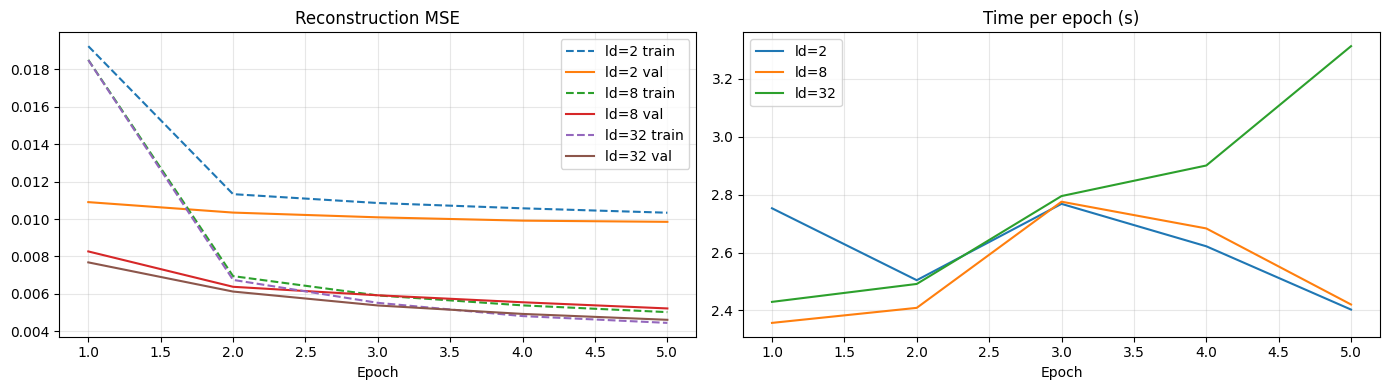

In [ ]:
#Визуализация кривых обучения
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ld, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["train_loss"], "--", label=f"ld={ld} train")
    axes[0].plot(hist["epoch"], hist["val_loss"], "-", label=f"ld={ld} val")
    axes[1].plot(hist["epoch"], hist["time"], "-", label=f"ld={ld}")

axes[0].set_title("Reconstruction MSE")
axes[0].set_xlabel("Epoch")
axes[0].grid(alpha=0.3)
axes[1].set_title("Time per epoch (s)")
axes[1].set_xlabel("Epoch")
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

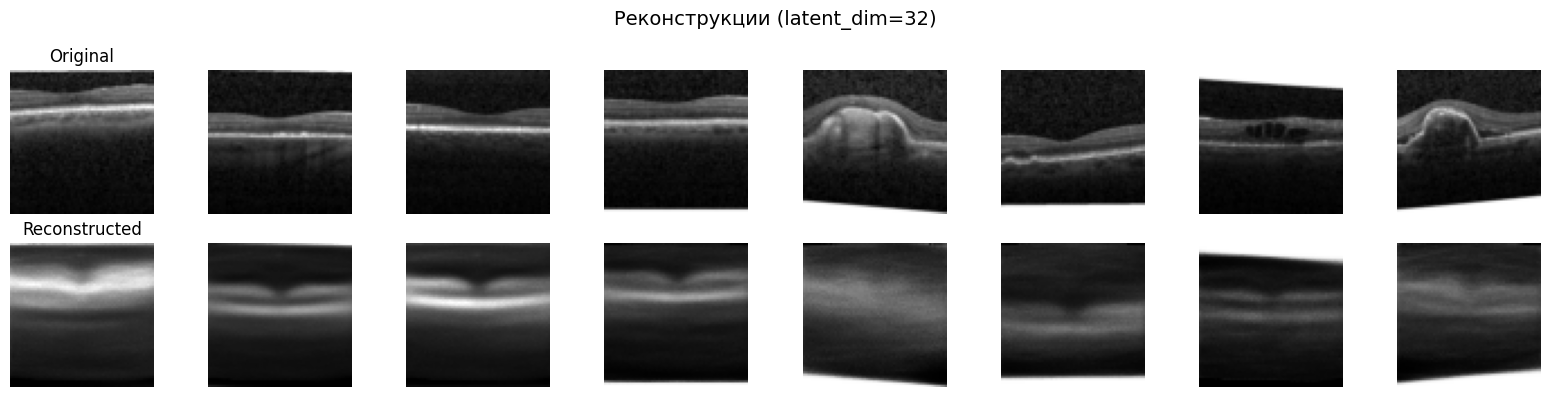

In [ ]:
#Визуализация реконструкций (оригинал vs восстановление)
model = models[32]
model.eval()
x_batch, _ = next(iter(test_loader))
x_batch = x_batch.to(device)

with torch.no_grad():
    x_hat, _ = model(x_batch)

n = 8
fig, axes = plt.subplots(2, n, figsize=(16, 4))
for i in range(n):
    axes[0, i].imshow(x_batch[i, 0].cpu(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(x_hat[i, 0].cpu(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_title("Original")
axes[1, 0].set_title("Reconstructed")
plt.suptitle("Реконструкции (latent_dim=32)", fontsize=14)
plt.tight_layout()
plt.show()

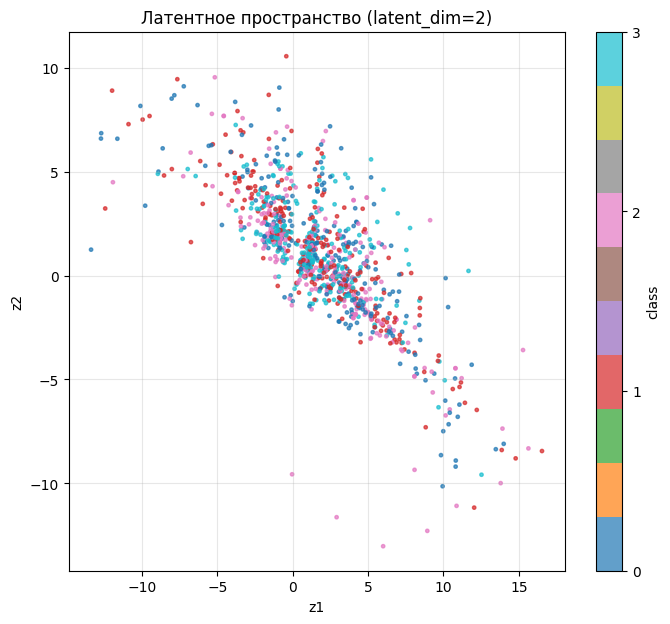

In [ ]:
#Визуализация латентного пространства (dim=2)
@torch.no_grad()
def get_latents(model, loader):
    model.eval()
    Z, Y = [], []
    for xb, yb in loader:
        _, z = model(xb.to(device))
        Z.append(z.cpu().numpy())
        Y.append(yb.numpy())
    return np.concatenate(Z), np.concatenate(Y)

Z2, Y2 = get_latents(models[2], test_loader)
plt.figure(figsize=(8, 7))
sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=Y2, cmap="tab10", s=6, alpha=0.7)
plt.colorbar(sc, ticks=range(4), label="class")
plt.title("Латентное пространство (latent_dim=2)")
plt.xlabel("z1")
plt.ylabel("z2")
plt.grid(alpha=0.3)
plt.show()

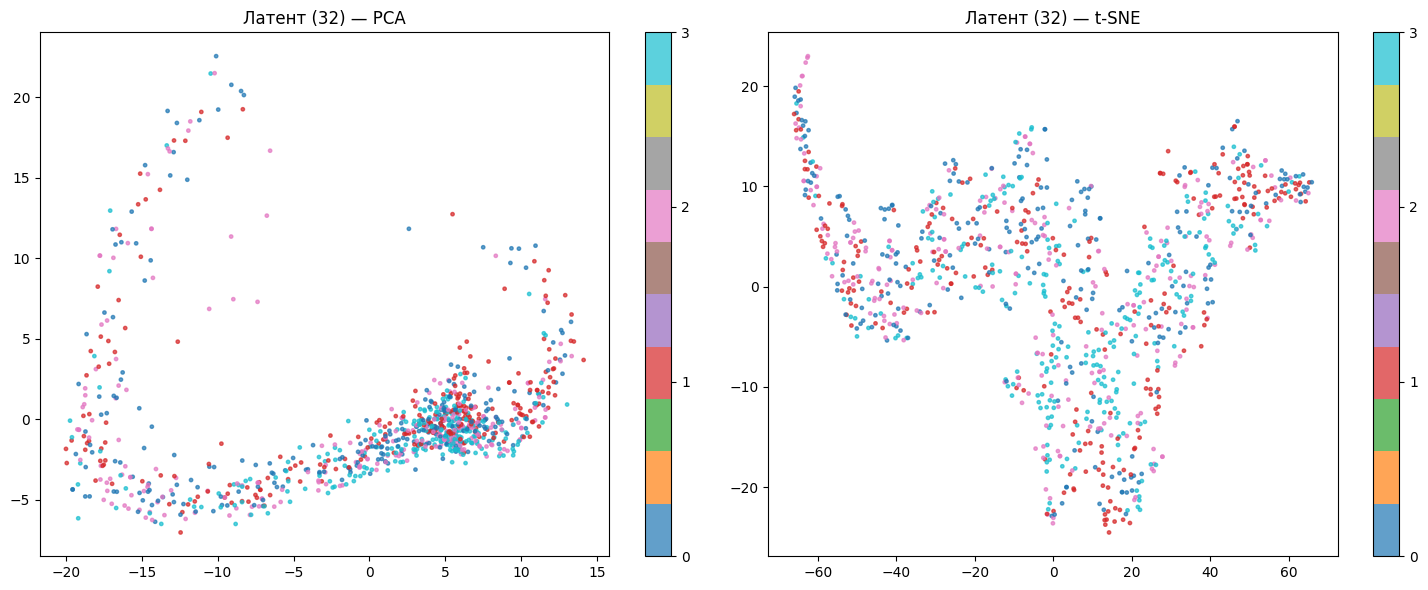

In [ ]:
#Визуализация латентного пространства (dim=32) через PCA и t-SNE
Z32, Y32 = get_latents(models[32], test_loader)

idx = np.random.choice(len(Z32), 1000, replace=False)
Z_sample, Y_sample = Z32[idx], Y32[idx]

Z_pca = PCA(n_components=2, random_state=42).fit_transform(Z_sample)
Z_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(Z_sample)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (Z, ttl) in zip(axes, [(Z_pca, "PCA"), (Z_tsne, "t-SNE")]):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=Y_sample, cmap="tab10", s=6, alpha=0.7)
    ax.set_title(f"Латент (32) — {ttl}")
    plt.colorbar(sc, ax=ax, ticks=range(4))

plt.tight_layout()
plt.show()

## 5. Ретроспектива и следующие шаги

**Основные результаты и анализ графиков:**
- **Достижение SMART-цели:** Все три модели уверенно преодолели целевой порог `MSE < 0.02` на тестовой выборке OCTMNIST. При увеличении размерности скрытого слоя с `2` до `32` ошибка на тесте снизилась более чем в 2.1 раза — с **0.00985** до **0.00461** (при этом для `dim=8` ошибка составила **0.00522**, а общее число параметров осталось около **2.13 млн**).
- **Высокая скорость обучения на GPU:** Предварительное кэширование тензоров в память и запуск на видеокарте **Tesla T4** позволили сократить время одной эпохи до **2.4–3.3 секунд**, а полный цикл обучения каждой модели из 5 эпох занял всего **12.6–13.9 секунд**.
- **Качество реконструкции (`latent_dim=32`):** На сравнительных снимках видно, что автоэнкодер точно восстанавливает общую геометрию, толщину и контраст слоёв сетчатки, сглаживая лишь высокочастотный спекл-шум, характерный для ОКТ-изображений.
- **Анализ латентного пространства:** На прямом 2D-графике (`latent_dim=2`) эмбеддинги вытягиваются в диагональное облако, где здоровые снимки (`NORMAL`, класс 3) смещаются в верхнюю левую часть, а патологии (`CNV`, класс 0) — в нижнюю правую. При переходе к `latent_dim=32` проекции **PCA** (изогнутая дуга) и **t-SNE** (волнообразное непрерывное многообразие) показывают более выраженное локальное группирование клинических классов без использования меток при обучении.

**Идеи для дальнейшего развития (Backlog):**
- [ ] Перейти от полносвязного автоэнкодера к **свёрточному (ConvAE)** — это существенно сократит число параметров (сейчас >2.1 млн из-за входа 64×64) и позволит точнее восстанавливать мелкие друзы и отёки сетчатки.
- [ ] Протестировать **вариационный автоэнкодер (VAE)** для получения более гладкого и регулярного латентного пространства.
- [ ] Провести сравнение с **PCA baseline**, чтобы количественно оценить выигрыш нелинейного сжатия при одинаковой размерности.
- [ ] Добавить **планировщик шага обучения (`ReduceLROnPlateau`)** и увеличить число эпох с использованием **Early Stopping**.

**Выводы по процессу работы (Ретроспектива):**
- Предварительная подготовка данных в `TensorDataset` устранила узкое место при чтении с диска и позволила полностью загрузить GPU T4.
- Фиксация `SEED = 42` обеспечила воспроизводимость всех графиков и таблиц при перезапуске ноутбука.
- Автоматическое логирование результатов в единую таблицу `results_df` упростило сопоставление степени сжатия и точности реконструкции.
